<a href="https://colab.research.google.com/github/MoisesNb7/analisis_geoespacial_museos_mexico/blob/main/Reto_Mapa_cultural_MoisesNavarrete.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Reto: Mapa cultural: análisis geoespacial de la cobertura de museos en México**


---


Identificar y analizar información geoespacial utilizando Python y GeoPandas para resolver un problema e cobertura cultural. Desarrollará habilidades para manipular datos geográficos, visualizarlos en un mapa y extraer conclusiones que apoyen la toma de decisiones estratégicas.

# Análisis Geoespacial de Cobertura de Museos en México

Investigación territorial sobre la distribución espacial de museos frente a la delimitación de los estados de la República Mexicana, con el fin de detectar brechas de cobertura cultural y orientar posibles zonas de expansión[cite: 4, 5].

## Propósito de la investigación
- Integrar información geoespacial de los polígonos estatales (GeoJSON) y puntos de ubicación de museos (`museos_mx.csv` con coordenadas válidas y sistema de referencia `EPSG:4326`)[cite: 4, 5].
- Analizar la distribución y concentración espacial de recintos culturales por entidad federativa[cite: 4, 5].
- Representar los resultados en mapas para facilitar la lectura territorial y respaldar decisiones estratégicas de cobertura[cite: 4, 5].

## Librerías utilizadas
- **`pandas` (`pd`):** Carga, inspección y manipulación de datos tabulares de museos[cite: 5].
- **`geopandas` (`gpd`):** Manejo de datos geoespaciales, conversión de geometrías, sistema de coordenadas (`EPSG:4326`) y operaciones sobre `GeoDataFrame`[cite: 5].
- **`matplotlib.pyplot` (`plt`):** Construcción y personalización de mapas y visualizaciones geográficas[cite: 5].

In [ ]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

3.- Carga los datos de la localización de los Estados de la República Mexicana y de los museos como GeoDataFrames. Asegúrate de convertir correctamente la columna de geometría para los estados y para los museos. En el caso de los museos considera que al cargarlos debes usar un crs='epsg:4326’ para que corresponda a lo almacenado en el archivo.

In [ ]:
museos_df = pd.read_csv('/content/museos_mx.csv')
url = 'https://firebasestorage.googleapis.com/v0/b/tlg-prod.appspot.com/o/assets%2Ffile%2F0.zzazj3wxhfi0.3p7ogylw3ucestados_mx.geojson?alt=media&token=cec87a2e-41f0-44e0-9c5f-e894b23728da'
estados_mex = gpd.read_file(url)

museos_mex = gpd.GeoDataFrame(
    museos_df,
    geometry=gpd.points_from_xy(museos_df["longitud"], museos_df["latitud"]),
    crs="epsg:4326"
)

4._ Agrega una columna a los estados que indique la región a la que pertenecen y separa el GeoDataFrame por regiones en lugar de por estados:

a) Centro: Tlaxcala, Puebla, CDMX, Morelos, Estado de México e Hidalgo
b) Centro Oeste: Jalisco, Michoacán, Colima, Aguascalientes,
c) Nayarit, Zacatecas, San Luis Potosí, Guanajuato y Querétaro.
d) Noreste: Chihuahua, Coahuila, Nuevo León, Tamaulipas y Durango
e) Noroeste: Baja California Norte, Baja California Sur, Sonora y Sinaloa
f) Sureste: Guerrero, Veracruz, Oaxaca, Tabasco, Chiapas, Campeche, Yucatán y Quintana Roo

In [ ]:
estados_mex['region'] = ['centro oeste', 'centro oeste', 'centro', 'centro', 'centro',
                     'centro', 'centro', 'centro', 'noreste', 'noreste', 'noreste',
                     'noroeste', 'centro oeste', 'centro oeste', 'centro oeste',
                     'centro oeste', 'centro oeste', 'noreste', 'noreste', 'sureste',
                     'sureste', 'noroeste', 'sureste', 'centro oeste', 'sureste', 'sureste', 'sureste',
                     'noroeste', 'noroeste', 'centro oeste', 'sureste', 'sureste']

estados_mex = estados_mex.dissolve(by='region').reset_index()

5. Crea un buffer de 50 km alrededor de los puntos de localización de cada museo, que represente su área aproximada de cobertura cultural.

6. Asegura que todos los GeoDataFrames utilicen el crs='epsg:3395’ para que se grafiquen correctamente.

In [ ]:
estados_mex = estados_mex.to_crs(epsg=3395)
museos_mex = museos_mex.to_crs(epsg=3395)

museos_mex['zona_influencia'] = museos_mex.geometry.buffer(50000)

zona_influencia = gpd.GeoDataFrame(
    museos_mex[['museo_nombre']],
    geometry=museos_mex['zona_influencia'],
    crs=museos_mex.crs
)

7. Crea un mapa estático que muestre:

a) Las geometrías de los estados coloreadas por región.

b) Los buffers de cobertura de museos.

c) Los puntos que representan cada museo.

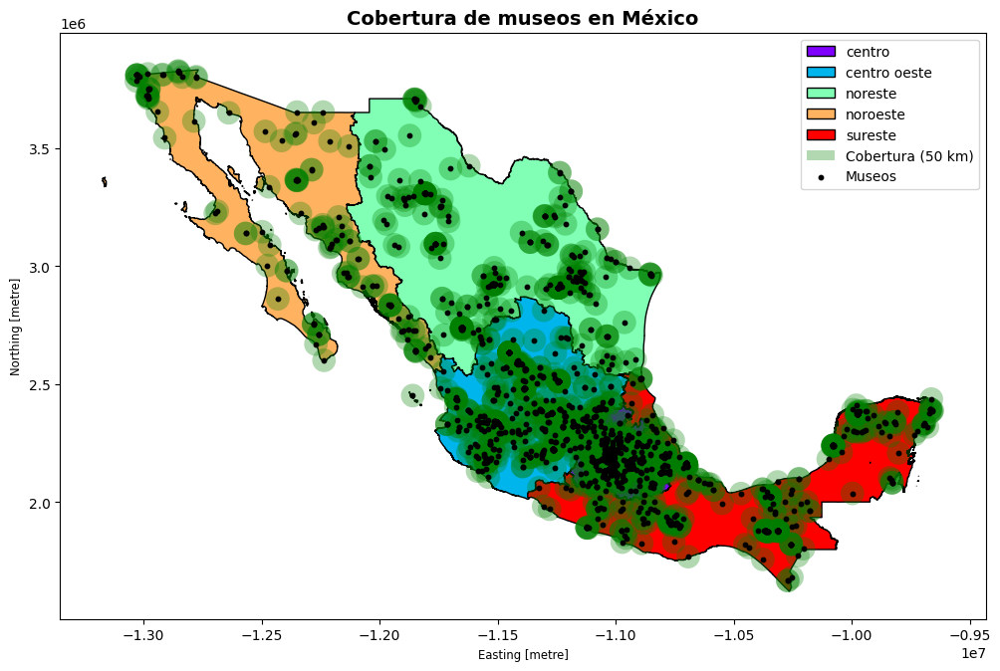

In [ ]:
fig, ax = plt.subplots(figsize=(12, 8))

estados_mex.plot(ax=ax,column='region', cmap='rainbow', edgecolor='black')
zona_influencia.plot(ax=ax, color='green', alpha=0.3, label='Cobertura (50 km)')
museos_mex.plot(ax=ax, color='black', markersize=10, label='Museos')

plt.title("Cobertura de museos en México", fontsize=14, fontweight='bold')
plt.legend(loc='upper right')
plt.show()

8. Crea un mapa interactivo que muestre:

a) Los puntos que representan cada museo.

Puedes usar folium o GeoDataFrame.explore() para esta visualización.

In [ ]:
m = estados_mex.explore(
    cmap='rainbow',
    column='region',
    tooltip=[ 'region'],
    popup=True,
    tiles='https://server.arcgisonline.com/ArcGIS/rest/services/World_Street_Map/MapServer/tile/{z}/{y}/{x}',
    attr='Esri')

In [ ]:
museos_mex.explore(
    m=m,
    color="blue",
    tooltip=['museo_nombre'])

9.- Compara ambos mapas y elige el que te permita una mejor visualización.


### Comparación de Mapas y Elección

Al analizar ambas representaciones cartográficas, podemos notar ventajas y desventajas claras en cada una:

1. **Mapa Estático (Matplotlib / GeoPandas.plot)**:
   * **Ventajas**: Es ideal para reportes formales, publicaciones académicas o impresas debido a que su diseño es fijo, consistente y no requiere conexión a internet ni potencia de cómputo para interactuar.
   * **Desventajas**: Al superponerse las áreas de influencia de 50 km (buffers) de más de 1600 museos, la visualización se satura y se vuelve difícil identificar puntos específicos o leer etiquetas individuales.

2. **Mapa Interactivo (Folium / explore)**:
   * **Ventajas**: Permite hacer zoom sobre zonas densas (como el centro del país) y desplegar información contextual (tooltips y popups con el nombre del museo y la región) al pasar el cursor o hacer clic. Esto resuelve por completo el problema de la saturación de datos.
   * **Desventajas**: Requiere mayor capacidad de procesamiento en el navegador y una conexión activa para cargar los mapas base.

**Elección**: El **mapa interactivo** es el que permite una **mejor visualización**, ya que facilita la exploración detallada de la distribución geográfica y la consulta de atributos específicos de cada museo individualmente sin perder la perspectiva regional.

10.- Identifica las regiones en dónde se requiere más cobertura y responde la pregunta:

¿En qué regiones del país (centro, centro oeste, noreste, noroeste, sureste) no hay suficiente cobertura cultural y sería más urgente abrir un nuevo museo?

In [ ]:
import geopandas as gpd

# 1. Realizar una unión espacial (spatial join) para contar cuántos museos caen en cada región
# Aseguramos que ambos tengan el mismo CRS (EPSG:3395)
museos_con_region = gpd.sjoin(museos_mex, estados_mex, how='left', predicate='within')

# 2. Contar museos por región
conteo_museos = museos_con_region.groupby('region').size().reset_index(name='total_museos')

# 3. Calcular el área total de cada región en kilómetros cuadrados para dimensionar la cobertura
estados_mex['area_km2'] = estados_mex.geometry.area / 1e6

# Unir los datos para obtener una métrica de densidad (Museos por cada 10,000 km²)
analisis_cobertura = estados_mex[['region', 'area_km2']].merge(conteo_museos, on='region')
analisis_cobertura['museos_por_10k_km2'] = (analisis_cobertura['total_museos'] / analisis_cobertura['area_km2']) * 10000

display(analisis_cobertura.sort_values(by='museos_por_10k_km2'))

,region,area_km2,total_museos,museos_por_10k_km2
3,noroeste,497980.430063,115,2.309328
2,noreste,839026.665401,250,2.979643
4,sureste,517561.687985,334,6.453337
1,centro oeste,409927.605436,426,10.392079
0,centro,98719.688494,504,51.053646


### Análisis y Conclusión sobre la Cobertura Cultural

Con base en el análisis espacial y el cálculo de la densidad de museos por cada 10,000 $km^2$, los resultados obtenidos son los siguientes:

| Región | Área ($km^2$) | Total de Museos | Museos por cada 10,000 $km^2$ |
| :--- | :---: | :---: | :---: |
| **Noroeste** | 497,980.43 | 115 | **2.31** |
| **Noreste** | 839,026.67 | 250 | **2.98** |
| **Sureste** | 517,561.69 | 334 | **6.45** |
| **Centro Oeste** | 409,927.61 | 426 | **10.39** |
| **Centro** | 98,719.69 | 504 | **51.05** |

### **Respuesta a la pregunta:**
¿En qué regiones del país no hay suficiente cobertura cultural y sería más urgente abrir un nuevo museo?

1. **Región Noroeste (La más crítica):** Es la región con **menor cobertura cultural de todo el país**, contando con apenas **2.31 museos por cada 10,000 $km^2$** y tan solo 115 museos en total para un área sumamente extensa. Por lo tanto, esta es la región donde es **más urgente** abrir un nuevo museo.
2. **Región Noreste (Segunda prioridad):** A pesar de tener un total de 250 museos, su enorme extensión territorial de más de 839,000 $km^2$ (la más grande de México) resulta en una baja densidad de cobertura de apenas **2.98 museos por cada 10,000 $km^2$**.

**Conclusión:**
Mientras que la región **Centro** goza de una altísima centralización cultural (más de 51 museos por cada 10,000 $km^2$), el **Norte de México (tanto el Noroeste como el Noreste)** presenta un rezago geográfico y una dispersión muy grande que limita el acceso de la población a estos espacios, haciendo prioritaria la descentralización y apertura de nuevos museos en estos territorios.